In [3]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [4]:
# ==========================================
# Завдання 1: Підготовка даних
# ==========================================
wine = load_wine()

# Перетворення у pandas.DataFrame
df = pd.DataFrame(data=wine.data, columns=wine.feature_names)
df["target"] = wine.target

X = df.drop("target", axis=1)
y = df["target"]

# Розділення даних на навчальну і тестову вибірки (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Масштабування ознак за допомогою StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Для візуалізації всього датасету у Завданні 2 також масштабуємо повний набір X
X_all_scaled = scaler.fit_transform(X)

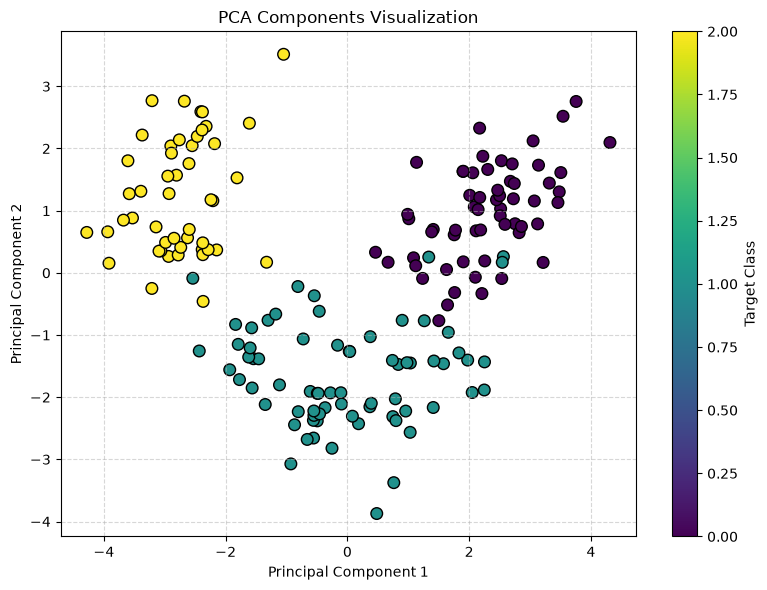

In [5]:
# ==========================================
# Завдання 2: Застосування PCA (n_components=2) та візуалізація
# ==========================================
pca_2 = PCA(n_components=2, random_state=42)
X_pca_2 = pca_2.fit_transform(X_all_scaled)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    X_pca_2[:, 0], X_pca_2[:, 1], c=y, cmap="viridis", edgecolor="k", s=70
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Components Visualization")
plt.colorbar(scatter, label="Target Class")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [6]:
# ==========================================
# Завдання 3: Оцінка впливу кількості компонент на якість класифікації
# ==========================================
components_list = [2, 5, 10]
accuracies = []

print("Результати класифікації (LogisticRegression):")
for n in components_list:
    pca = PCA(n_components=n, random_state=42)
    X_train_pca = pca.fit_transform(X_train_scaled)
    X_test_pca = pca.transform(X_test_scaled)

    clf = LogisticRegression(random_state=42, max_iter=1000)
    clf.fit(X_train_pca, y_train)

    y_pred = clf.predict(X_test_pca)
    acc = accuracy_score(y_test, y_pred)
    accuracies.append(acc)

    print(f"Кількість компонент PCA = {n:2d} | Accuracy: {acc:.4f}")

Результати класифікації (LogisticRegression):
Кількість компонент PCA =  2 | Accuracy: 0.9167
Кількість компонент PCA =  5 | Accuracy: 0.9722
Кількість компонент PCA = 10 | Accuracy: 0.9722


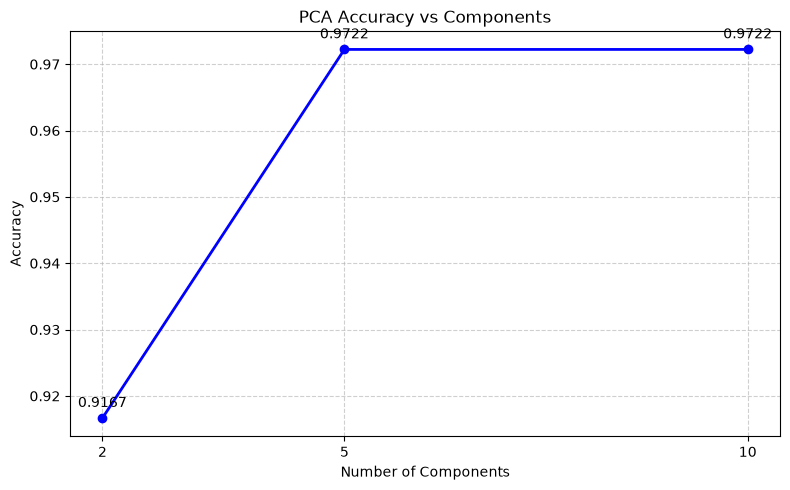

In [7]:
# ==========================================
# Завдання 4: Графік залежності точності від числа компонент
# ==========================================
plt.figure(figsize=(8, 5))
plt.plot(
    components_list, accuracies, marker="o", linestyle="-", color="b", linewidth=2
)
plt.xticks(components_list)
plt.xlabel("Number of Components")
plt.ylabel("Accuracy")
plt.title("PCA Accuracy vs Components")
plt.grid(True, linestyle="--", alpha=0.6)

# Додаємо підписи значень над точками для наочності
for n, acc in zip(components_list, accuracies):
    plt.annotate(
        f"{acc:.4f}",
        (n, acc),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
    )

plt.tight_layout()
plt.savefig("pca_accuracy_results.png", dpi=300)
plt.show()